# Lab 14: Guessing a Person's Weight Level from Eating Habits and Daily Life

**Name:** ROHAITKUMAR  **Roll No:** 26MSDS040

## 1. Problem Definition

Being overweight is a health problem in many countries. A quick check that uses only eating habits and daily life could warn people early, before they visit a doctor. In this project, I build a model that guesses a person's weight level from their answers about food, exercise and daily routine.

| Item | Details |
|---|---|
| **Task type** | Multi-class classification (7 classes) |
| **Dataset** | Estimation of Obesity Levels Based on Eating Habits and Physical Condition (UCI Machine Learning Repository, id 544) |
| **Dataset link** | https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition |
| **Size** | 2,111 rows and 17 columns (16 inputs + 1 target) |
| **Target column** | `NObesity` (7 weight levels) |
| **Metric** | Macro F1-score (accuracy is shown as a second number) |

**The 7 weight levels:** Insufficient Weight, Normal Weight, Overweight Level I, Overweight Level II, Obesity Type I, Obesity Type II, Obesity Type III.

**Why macro F1?** There are 7 classes and each one matters equally. Accuracy can look good even when the model is bad on one class. Macro F1 gives every class the same weight, and it counts both kinds of mistakes: missing a person and giving a wrong label.

## Steps in this notebook

1. Import libraries
2. Load the data
3. Two important data problems (read this!)
4. Remove Height and Weight, then lock away the test set
5. Data exploration (training data only)
6. Data preparation with a pipeline (no leakage)
7. Baseline model
8. Compare 4 models with 5-fold cross-validation
9. Tune the best model
10. Final test on the locked test set
11. Error analysis
12. Limitations, fairness and ethics
13. Project record table
14. Viva preparation
15. Report outline
16. Numbers to double-check

## Step 1: Import Libraries

We load the tools we need. `pandas` is for tables, `matplotlib` and `seaborn` are for charts, and `sklearn` has the machine learning tools.

In [1]:
# pandas and numpy: work with tables and numbers
import pandas as pd
import numpy as np

# matplotlib and seaborn: draw charts
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn tools to split the data and check the models
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV

# sklearn tools to clean and change the data
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# the models we will try
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# tools to measure how good the model is
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

# hide warning messages so the notebook is easy to read
import warnings
warnings.filterwarnings("ignore")

# make the charts look nice
sns.set_style("whitegrid")

# show all columns when we print a table
pd.set_option("display.max_columns", 30)

print("All libraries loaded.")

All libraries loaded.


## Step 2: Load the Data

1. Go to the dataset link above and click **Download**. Unzip the file.
2. In Google Colab, click the **folder icon** on the left side and upload the CSV file.
3. Run the cell below.

The file name is usually `ObesityDataSet_raw_and_data_sinthetic.csv`. If your file has a different name, change it in the code.

In [2]:
# read the CSV file into a table (called a DataFrame)
data = pd.read_csv("ObesityDataSet_raw_and_data_sinthetic.csv")

print("Data loaded.")

Data loaded.


**Optional:** If you do not want to upload the file, you can load the data straight from UCI. To use it, remove the `#` signs at the start of the lines and run the cell.

In [3]:
# OPTIONAL: load the data directly from UCI (needs internet)
# !pip install ucimlrepo
# from ucimlrepo import fetch_ucirepo
# obesity = fetch_ucirepo(id=544)
# data = pd.concat([obesity.data.features, obesity.data.targets], axis=1)

In [4]:
# In some versions of the file the target column is called "NObeyesdad".
# We rename it to "NObesity" so that the name is the same everywhere.
if "NObeyesdad" in data.columns:
    data = data.rename(columns={"NObeyesdad": "NObesity"})

# the 7 weight levels, from lightest to heaviest (we use this order in charts)
class_order = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I",
               "Overweight_Level_II", "Obesity_Type_I", "Obesity_Type_II",
               "Obesity_Type_III"]

# check that every label is in the data (the spelling can change between file versions)
for name in class_order:
    if name not in data["NObesity"].unique():
        print("Warning: this label was not found:", name)

# give each level a number: 0 = lightest, 6 = heaviest
order_number = {}
for i in range(len(class_order)):
    order_number[class_order[i]] = i

# show the size of the data and the first 5 rows
print("Rows and columns:", data.shape)
data.head()

Rows and columns: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObesity
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


## Step 3: Two Important Data Problems

**Problem 1: Most of the rows were made by a computer.**
About 77% of the rows in this dataset were made by a computer (using a method called SMOTE) from real survey answers. Only about 23% are real answers. Computer-made rows are very close copies of real rows. This means a row in the test set may have a near twin in the training set, so our scores may look better than they would in real life. We will say this clearly in our report.

**Problem 2: Height and Weight give away the answer.**
The weight level in this dataset is worked out from height and weight (this is called BMI). If we keep these two columns, the model will just copy the formula and learn nothing useful about eating habits. So we **remove Height and Weight** and use only eating habits and daily-life columns.

## Step 4: Remove Height and Weight, Then Lock Away the Test Set

We do this **first**, before looking at the data in detail.

- We keep 20% of the rows as a **test set**. We will not look at it until the very end.
- `stratify=y` keeps the same share of each class in both parts.
- `random_state=42` makes the split the same every time we run it.

If we looked at the test data while building the model, our final score would be too good to trust. This is called **data leakage**.

In [5]:
# remove the two columns that give away the answer
data = data.drop(columns=["Height", "Weight"])

# X = the input columns, y = the answer column
X = data.drop(columns=["NObesity"])
y = data["NObesity"]

# split: 80% for training, 20% for the final test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])
print("Number of input columns:", X_train.shape[1])

Training rows: 1688
Test rows: 423
Number of input columns: 14


In [33]:
print(data["NObesity"].value_counts())

NObesity
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64


## Step 5: Data Exploration (Training Data Only)

From now on, we explore **only the training data**. The test set stays locked.

In [6]:
# put the inputs and the answer together in one table (training data only)
train_data = X_train.copy()
train_data["NObesity"] = y_train

# size of the training data
print("Shape (rows, columns):", train_data.shape)
print()

# first 5 rows
train_data.head()

Shape (rows, columns): (1688, 15)



,Gender,Age,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObesity
459,Male,19.000000,yes,yes,2.000000,3.000000,Frequently,no,3.000000,no,1.000000,2.000000,Frequently,Public_Transportation,Overweight_Level_I
426,Male,22.000000,no,no,2.000000,3.000000,Sometimes,no,3.000000,no,1.000000,1.000000,no,Public_Transportation,Normal_Weight
326,Male,18.000000,yes,yes,3.000000,3.000000,Sometimes,no,2.000000,no,3.000000,0.000000,Sometimes,Public_Transportation,Normal_Weight
971,Male,19.506389,yes,yes,2.793561,3.788602,Sometimes,no,2.429059,no,2.094542,0.393358,Sometimes,Public_Transportation,Overweight_Level_I
892,Female,17.085250,no,yes,1.972545,2.339614,Sometimes,no,1.711074,yes,0.095517,1.191053,Sometimes,Public_Transportation,Overweight_Level_I


In [7]:
# column names, data types, and how many values are filled in
train_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1688 entries, 459 to 478
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          1688 non-null   object 
 1   Age                             1688 non-null   float64
 2   family_history_with_overweight  1688 non-null   object 
 3   FAVC                            1688 non-null   object 
 4   FCVC                            1688 non-null   float64
 5   NCP                             1688 non-null   float64
 6   CAEC                            1688 non-null   object 
 7   SMOKE                           1688 non-null   object 
 8   CH2O                            1688 non-null   float64
 9   SCC                             1688 non-null   object 
 10  FAF                             1688 non-null   float64
 11  TUE                             1688 non-null   float64
 12  CALC                            1688 n

In [8]:
# summary numbers for the number columns (average, smallest, biggest...)
train_data.describe()

,Age,FCVC,NCP,CH2O,FAF,TUE
count,1688.000000,1688.000000,1688.000000,1688.000000,1688.000000,1688.000000
mean,24.310222,2.428400,2.688133,2.017965,1.020554,0.653900
std,6.392643,0.529317,0.775336,0.613215,0.847575,0.600574
min,15.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.918283,2.000000,2.663260,1.622384,0.132315,0.000000
50%,22.725431,2.414600,3.000000,2.000000,1.000000,0.619850
75%,26.000000,3.000000,3.000000,2.500827,1.683612,1.000000
max,61.000000,3.000000,4.000000,3.000000,3.000000,2.000000


### Missing values and repeated rows

Missing values can break a model, so we count them. We also count rows that appear more than once.

In [9]:
# count missing values in each column
missing = train_data.isnull().sum()
print("Missing values per column:")
print(missing)
print()
print("Total missing values:", missing.sum())

# count rows that are exact copies of another row
print("Repeated rows:", train_data.duplicated().sum())

Missing values per column:
Gender                            0
Age                               0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObesity                          0
dtype: int64

Total missing values: 0
Repeated rows: 20


### Class balance

We check how many rows each weight level has. If one class is very small, accuracy can be misleading.

In [10]:
# count the rows in each class, and also show the percent
class_counts = train_data["NObesity"].value_counts()
class_percent = train_data["NObesity"].value_counts(normalize=True) * 100

balance_table = pd.DataFrame({"Rows": class_counts, "Percent": class_percent.round(1)})
balance_table = balance_table.reindex(class_order)
balance_table

,Rows,Percent
NObesity,,
Insufficient_Weight,218,12.9
Normal_Weight,229,13.6
Overweight_Level_I,232,13.7
Overweight_Level_II,232,13.7
Obesity_Type_I,281,16.6
Obesity_Type_II,237,14.0
Obesity_Type_III,259,15.3


### Optional check: how many rows look computer-made?

In real survey answers, questions like "how many main meals do you eat" (`NCP`) get whole-number answers (1, 2, 3...). Computer-made rows often have decimals such as 2.45. We count how many rows have decimals in these columns. This is only a hint, and we do not use it to change the data.

In [11]:
# these columns should hold whole numbers in real survey answers
whole_number_columns = ["FCVC", "NCP", "CH2O", "FAF", "TUE"]

for column in whole_number_columns:
    # a value with a decimal part gives a remainder bigger than 0 when divided by 1
    has_decimal = (train_data[column] % 1) != 0
    percent = has_decimal.mean() * 100
    print(column, "-> rows with decimals:", round(percent, 1), "%")

FCVC -> rows with decimals: 39.8 %
NCP -> rows with decimals: 30.5 %
CH2O -> rows with decimals: 61.3 %
FAF -> rows with decimals: 57.6 %
TUE -> rows with decimals: 56.0 %


### Plot 1: How many rows in each weight level?

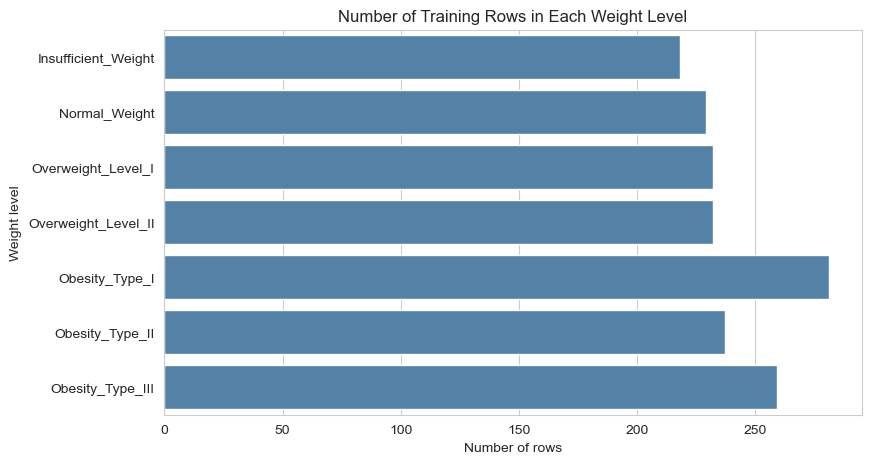

In [12]:
# bar chart: number of rows in each class
plt.figure(figsize=(9, 5))
sns.countplot(data=train_data, y="NObesity", order=class_order, color="steelblue")
plt.title("Number of Training Rows in Each Weight Level")
plt.xlabel("Number of rows")
plt.ylabel("Weight level")
plt.show()

**What we learned:** Look at the bar lengths. If they are all close to each other, the classes are balanced and plain accuracy is not misleading. This even spread is partly because the computer-made rows were added to balance the classes. *(Write 1-2 lines here about what you see in your chart.)*

### Plot 2: Age in each weight level

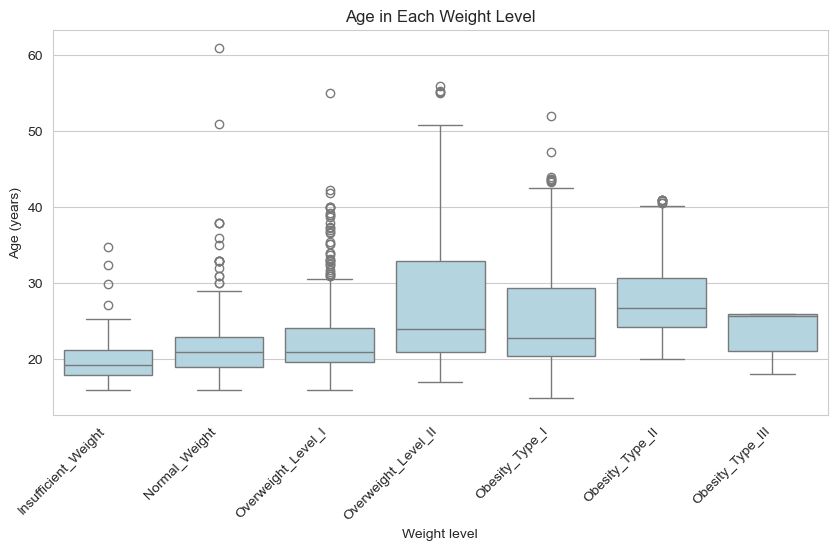

In [13]:
# box plot: how Age is spread inside each weight level
plt.figure(figsize=(10, 5))
sns.boxplot(data=train_data, x="NObesity", y="Age", order=class_order, color="lightblue")
plt.title("Age in Each Weight Level")
plt.xlabel("Weight level")
plt.ylabel("Age (years)")
plt.xticks(rotation=45, ha="right")
plt.show()

**What we learned:** The middle line of each box is the typical age for that level. Check whether the heavier levels have older people than the lighter levels, and whether the boxes overlap a lot. If they overlap a lot, Age alone cannot tell the levels apart. *(Write 1-2 lines here about what you see.)*

### Plot 3: Correlation heatmap

Correlation shows how strongly two number columns move together. A value near 1 or -1 is strong. A value near 0 means almost no link. We also add the weight level as a number (0 to 6) to see which columns go with it.

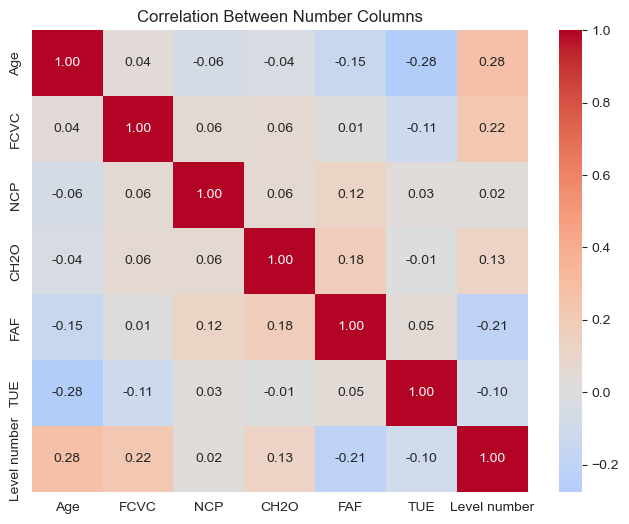

In [14]:
# turn the weight level into a number (0 = lightest, 6 = heaviest)
train_data["Level number"] = train_data["NObesity"].map(order_number)

# keep only the number columns
number_columns = train_data.select_dtypes(include="number")

# work out the correlation between every pair of columns
correlation = number_columns.corr()

# heat map of the correlations
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Number Columns")
plt.show()

**What we learned:** Look at the last row (`Level number`). Which columns have the biggest numbers there (ignoring the sign)? Those columns are the ones most linked with the weight level. Also check whether any two input columns are strongly linked with each other. *(Write 1-2 lines here about what you see.)*

### Plot 4: Eating high-calorie food often (FAVC) in each weight level

`FAVC` means "Do you eat high-calorie food often?" (yes or no).

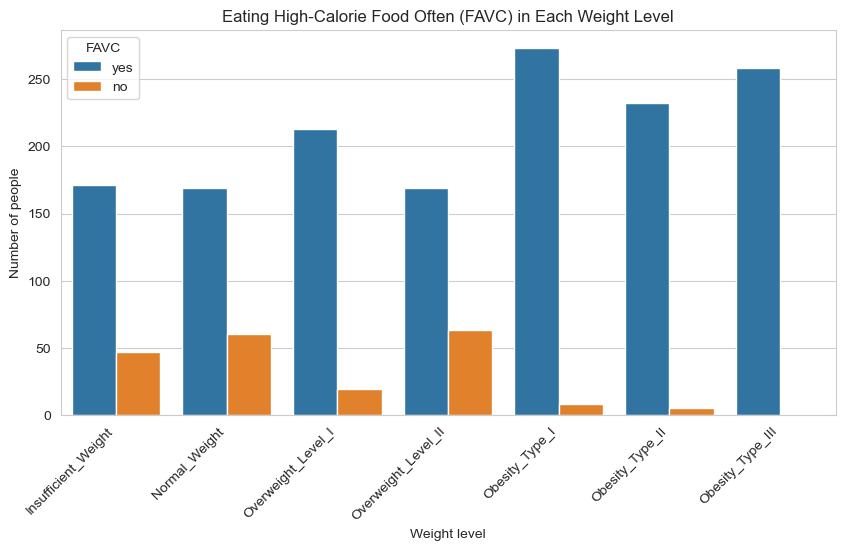

In [15]:
# bar chart: for each weight level, how many people said yes or no to FAVC
plt.figure(figsize=(10, 5))
sns.countplot(data=train_data, x="NObesity", hue="FAVC", order=class_order)
plt.title("Eating High-Calorie Food Often (FAVC) in Each Weight Level")
plt.xlabel("Weight level")
plt.ylabel("Number of people")
plt.xticks(rotation=45, ha="right")
plt.legend(title="FAVC")
plt.show()

**What we learned:** Check whether "yes" is much more common in the heavier levels. If the "yes" share is high in almost every level, then this column does not help much to separate the levels. *(Write 1-2 lines here about what you see.)*

### Plot 5: Eating between meals (CAEC) in each weight level

`CAEC` means "Do you eat anything between meals?" (no, sometimes, frequently, always).

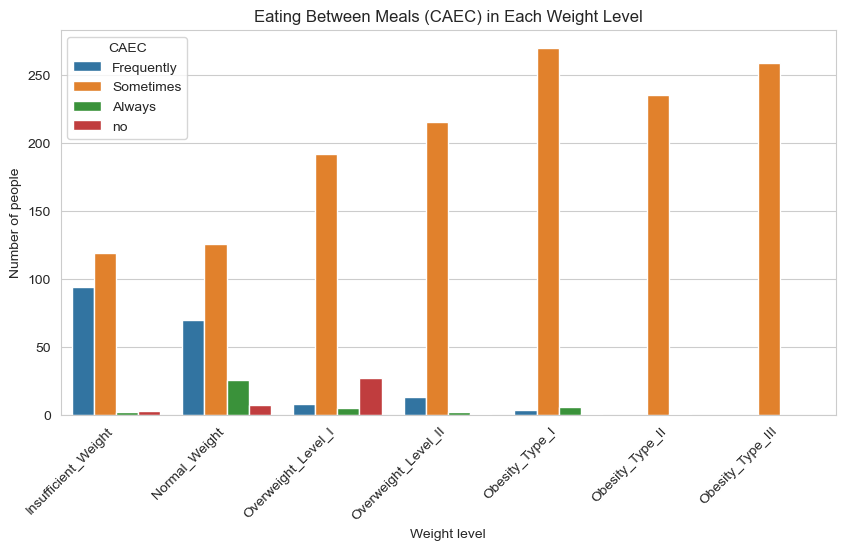

In [16]:
# bar chart: eating between meals in each weight level
plt.figure(figsize=(10, 5))
sns.countplot(data=train_data, x="NObesity", hue="CAEC", order=class_order)
plt.title("Eating Between Meals (CAEC) in Each Weight Level")
plt.xlabel("Weight level")
plt.ylabel("Number of people")
plt.xticks(rotation=45, ha="right")
plt.legend(title="CAEC")
plt.show()

**What we learned:** Look for levels where one answer is much bigger than the others. A column whose answers change a lot from level to level is useful for the model. *(Write 1-2 lines here about what you see.)*

## Step 6: Data Preparation with a Pipeline (No Leakage)

The model needs clean numbers. We do three jobs:

1. **Fill missing values.** Number columns get the middle value (median). Text columns get the most common answer.
2. **Scale the number columns** with `StandardScaler`, so big numbers (like Age) do not control small ones.
3. **Turn text into numbers** with `OneHotEncoder` (for example, Gender becomes two 0/1 columns).

**Why a pipeline?** A pipeline does all these jobs and the model fit in one chain. During cross-validation, the pipeline learns the median, the scale and the categories **only from the training part of each fold**. If we scaled all the data first, the scaler would see the validation rows, and that is data leakage. A pipeline stops this.

In [17]:
# find which columns are numbers and which are text
number_cols = X_train.select_dtypes(include="number").columns.tolist()
text_cols = X_train.select_dtypes(include="object").columns.tolist()

print("Number columns:", number_cols)
print("Text columns:", text_cols)

Number columns: ['Age', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
Text columns: ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']


In [18]:
# steps for number columns: fill missing values with the median, then scale
number_steps = Pipeline(steps=[
    ("fill", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

# steps for text columns: fill missing values with the most common answer, then one-hot encode
text_steps = Pipeline(steps=[
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

# join both groups of steps: each one is applied to its own columns
preprocessor = ColumnTransformer(transformers=[
    ("numbers", number_steps, number_cols),
    ("text", text_steps, text_cols)
])

print("Preprocessor is ready.")

Preprocessor is ready.


## Step 7: Baseline Model

A baseline is a very simple "model" that we must beat. The `DummyClassifier` with `most_frequent` always guesses the most common class. If our real models cannot do much better than this, they are not worth using.

We use **5-fold stratified cross-validation**. The training data is cut into 5 parts. The model trains on 4 parts and is checked on the 5th part. This is repeated 5 times. The 5 scores are then averaged.

In [19]:
# 5-fold cross-validation (keeps the class shares equal in every fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# baseline pipeline: the preprocessor + a model that always guesses the most common class
baseline_pipe = Pipeline(steps=[
    ("prep", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

# get the 5 macro F1 scores
baseline_scores = cross_val_score(baseline_pipe, X_train, y_train, cv=cv, scoring="f1_macro")

print("Baseline macro F1 for each fold:", baseline_scores.round(3))
print("Baseline mean macro F1:", round(baseline_scores.mean(), 3))
print("Baseline standard deviation:", round(baseline_scores.std(), 3))

Baseline macro F1 for each fold: [0.041 0.041 0.041 0.041 0.041]
Baseline mean macro F1: 0.041
Baseline standard deviation: 0.0


## Step 8: Compare 4 Models with 5-Fold Cross-Validation

We try four different models. Each one is placed in the same pipeline, and each one is checked with the same 5 folds, so the comparison is fair.

| Model | Short idea |
|---|---|
| Logistic Regression | Draws straight-line borders between classes |
| Decision Tree | Asks a chain of yes/no questions |
| Random Forest | Many decision trees vote together |
| KNN | Looks at the closest similar people |

We pick the best model from the **scores**, not from what we like.

In [20]:
# the models we want to compare
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "KNN": KNeighborsClassifier()
}

# empty lists to keep the results (the baseline goes first)
result_names = ["Baseline (most frequent)"]
result_means = [baseline_scores.mean()]
result_stds = [baseline_scores.std()]

# go through the models one by one
for name in models:
    # same pipeline for every model: preprocessor + model
    pipe = Pipeline(steps=[
        ("prep", preprocessor),
        ("model", models[name])
    ])

    # 5-fold cross-validation score
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro")

    # save the results
    result_names.append(name)
    result_means.append(scores.mean())
    result_stds.append(scores.std())
    print(name, "-> mean macro F1:", round(scores.mean(), 3))

# put the results into a table, best model on top
results_df = pd.DataFrame({
    "Model": result_names,
    "Mean macro F1": result_means,
    "Std": result_stds
})
results_df = results_df.sort_values("Mean macro F1", ascending=False)
results_df = results_df.round(3)
results_df

Logistic Regression -> mean macro F1: 0.574
Decision Tree -> mean macro F1: 0.717
Random Forest -> mean macro F1: 0.837
KNN -> mean macro F1: 0.721


,Model,Mean macro F1,Std
3,Random Forest,0.837,0.013
4,KNN,0.721,0.021
2,Decision Tree,0.717,0.014
1,Logistic Regression,0.574,0.013
0,Baseline (most frequent),0.041,0.000


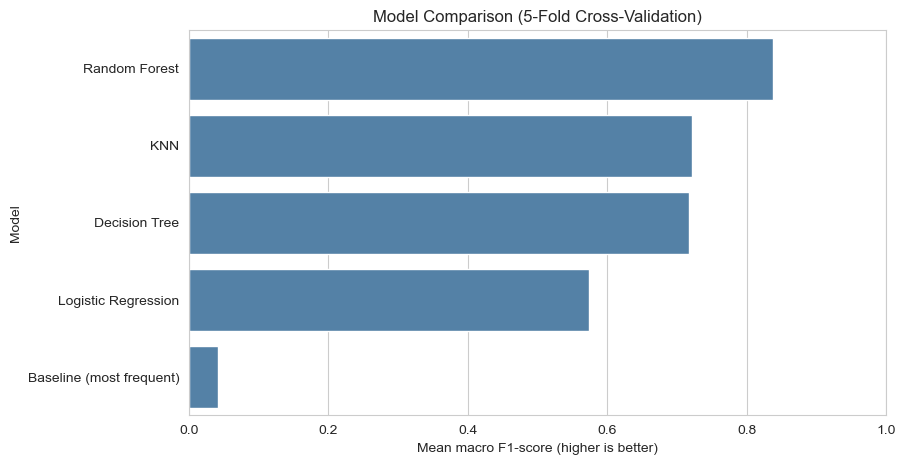

In [21]:
# bar chart of the mean macro F1 of each model
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Mean macro F1", y="Model", color="steelblue")
plt.title("Model Comparison (5-Fold Cross-Validation)")
plt.xlabel("Mean macro F1-score (higher is better)")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.show()

In [22]:
# pick the best real model (we skip the baseline row)
only_models = results_df[results_df["Model"] != "Baseline (most frequent)"]
best_name = only_models.iloc[0]["Model"]
best_cv_score = only_models.iloc[0]["Mean macro F1"]

print("Best model:", best_name)
print("Its mean macro F1 in cross-validation:", best_cv_score)

Best model: Random Forest
Its mean macro F1 in cross-validation: 0.837


**What we learned:** Compare the bars with the baseline bar. A model that is only a little better than the baseline is weak. Also look at the `Std` column: a small number means the model gives similar scores in all 5 folds, so it is stable. *(Write 1-2 lines here about which model won and why you think so.)*

## Step 9: Tune the Best Model

Every model has settings (called **hyperparameters**). We try different settings with `GridSearchCV`. It tests every combination in a small grid, using the same 5-fold cross-validation, and keeps the best one.

The grid below changes depending on which model won in Step 8. The test set is still locked.

In [23]:
# build a fresh pipeline with the best model
best_pipe = Pipeline(steps=[
    ("prep", preprocessor),
    ("model", models[best_name])
])

# choose the settings to try (the name "model__" points to the model inside the pipeline)
if best_name == "Random Forest":
    param_grid = {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_split": [2, 5]
    }
elif best_name == "Logistic Regression":
    param_grid = {
        "model__C": [0.1, 1, 10, 100]
    }
elif best_name == "Decision Tree":
    param_grid = {
        "model__max_depth": [5, 10, 15, None],
        "model__min_samples_leaf": [1, 2, 5]
    }
else:
    # KNN
    param_grid = {
        "model__n_neighbors": [3, 5, 7, 9, 11],
        "model__weights": ["uniform", "distance"]
    }

print("Settings we will try:")
print(param_grid)

Settings we will try:
{'model__n_estimators': [100, 200], 'model__max_depth': [None, 10, 20], 'model__min_samples_split': [2, 5]}


In [24]:
# search for the best settings using 5-fold cross-validation on the training data
grid = GridSearchCV(
    best_pipe,
    param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best cross-validation macro F1:", round(grid.best_score_, 3))
print("Before tuning it was:", best_cv_score)

Best settings: {'model__max_depth': 20, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best cross-validation macro F1: 0.841
Before tuning it was: 0.837


## Step 10: Final Test on the Locked Test Set

Now we open the test set. We use the tuned model **one time only**. We do not change anything after seeing this score.

In [25]:
# the tuned model (already trained on all the training data)
final_model = grid.best_estimator_

# predict the weight levels of the test rows
y_pred = final_model.predict(X_test)

# measure the result
test_f1 = f1_score(y_test, y_pred, average="macro")
test_accuracy = accuracy_score(y_test, y_pred)

print("Test macro F1:", round(test_f1, 3))
print("Test accuracy:", round(test_accuracy, 3))
print()
print(classification_report(y_test, y_pred, digits=3))

Test macro F1: 0.856
Test accuracy: 0.856

                     precision    recall  f1-score   support

Insufficient_Weight      0.891     0.907     0.899        54
      Normal_Weight      0.676     0.828     0.744        58
     Obesity_Type_I      0.806     0.829     0.817        70
    Obesity_Type_II      0.917     0.917     0.917        60
   Obesity_Type_III      1.000     0.985     0.992        65
 Overweight_Level_I      0.833     0.776     0.804        58
Overweight_Level_II      0.915     0.741     0.819        58

           accuracy                          0.856       423
          macro avg      0.862     0.855     0.856       423
       weighted avg      0.863     0.856     0.857       423



### Confusion matrix

Each row is the **true** level and each column is the **predicted** level. The numbers on the diagonal (top-left to bottom-right) are the correct guesses. Numbers away from the diagonal are mistakes.

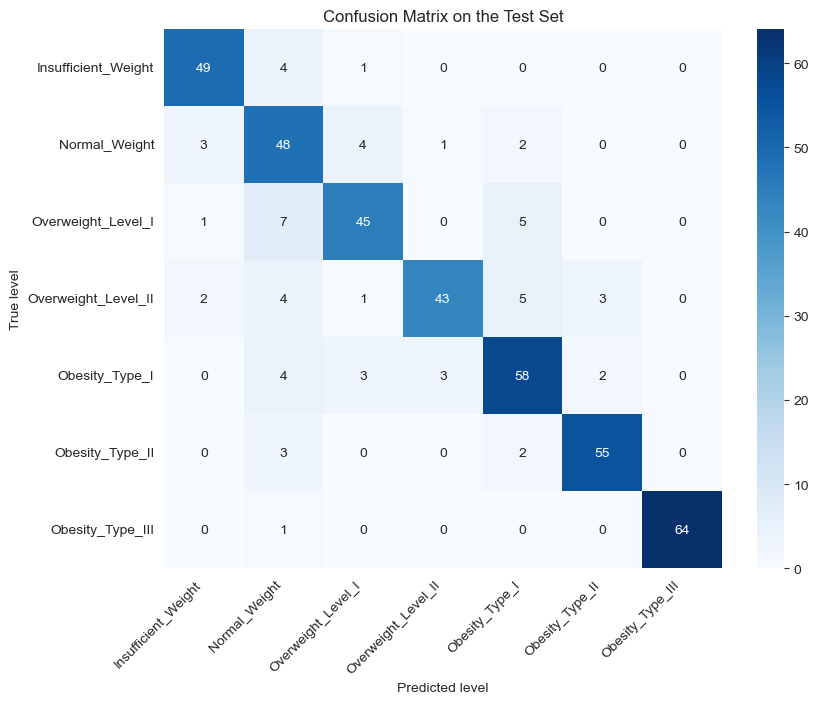

In [26]:
# count how many rows fall in each (true level, predicted level) pair
cm = confusion_matrix(y_test, y_pred, labels=class_order)

# draw it as a heat map
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_order, yticklabels=class_order)
plt.title("Confusion Matrix on the Test Set")
plt.xlabel("Predicted level")
plt.ylabel("True level")
plt.xticks(rotation=45, ha="right")
plt.show()

**What we learned:** Find the classes with the darkest diagonal boxes (the model is good there) and the classes with big numbers off the diagonal (the model is confused there). Mistakes next to the diagonal mean the model picked a nearby level. *(Write 2-3 lines here about what you see.)*

## Step 11: Error Analysis

Here we look at the rows the model got wrong, to understand **why** it fails. We show at least 10 wrong predictions. (If your model made fewer than 10 mistakes, say so in your report and look at the rows it was least sure about.)

In [27]:
# make a table of the test rows with the true and predicted levels
errors = X_test.copy()
errors["True label"] = y_test
errors["Predicted label"] = y_pred

# keep only the wrong predictions
errors = errors[errors["True label"] != errors["Predicted label"]]

print("Number of wrong predictions:", errors.shape[0], "out of", X_test.shape[0])
print("Share of mistakes:", round(errors.shape[0] / X_test.shape[0] * 100, 1), "%")

Number of wrong predictions: 61 out of 423
Share of mistakes: 14.4 %


In [28]:
# choose the main columns to show
columns_to_show = ["True label", "Predicted label", "Gender", "Age", "FAVC",
                   "FCVC", "NCP", "CAEC", "CH2O", "FAF", "TUE"]

# show the first 10 wrong predictions
errors[columns_to_show].head(10)

,True label,Predicted label,Gender,Age,FAVC,FCVC,NCP,CAEC,CH2O,FAF,TUE
1002,Overweight_Level_II,Obesity_Type_I,Male,24.108711,yes,2.000000,3.000000,Sometimes,2.879402,0.000000,0.322405
1305,Obesity_Type_I,Overweight_Level_II,Female,43.591999,yes,2.000000,3.000000,Sometimes,2.117346,0.000000,0.000000
77,Overweight_Level_II,Obesity_Type_I,Female,24.000000,yes,2.000000,3.000000,Sometimes,3.000000,0.000000,0.000000
1514,Obesity_Type_II,Obesity_Type_I,Male,25.314589,yes,1.588114,3.000000,Sometimes,2.115967,1.541072,0.000000
344,Obesity_Type_III,Normal_Weight,Male,18.000000,yes,3.000000,3.000000,Frequently,2.000000,2.000000,1.000000
127,Normal_Weight,Insufficient_Weight,Female,19.000000,yes,3.000000,1.000000,Sometimes,3.000000,1.000000,0.000000
1120,Overweight_Level_II,Obesity_Type_II,Male,23.806789,yes,2.992205,3.000000,Sometimes,2.413813,0.458237,0.688293
261,Overweight_Level_I,Normal_Weight,Female,28.000000,no,2.000000,3.000000,Frequently,2.000000,2.000000,0.000000
1382,Obesity_Type_I,Overweight_Level_I,Female,26.220065,yes,2.108163,1.231915,Sometimes,1.808127,0.000000,0.000000
68,Obesity_Type_II,Obesity_Type_I,Male,30.000000,yes,1.000000,3.000000,no,2.000000,0.000000,0.000000


### Which levels get mixed up the most?

In [29]:
# count each (true level -> predicted level) mistake pair
pair_counts = errors.groupby(["True label", "Predicted label"]).size()
pair_counts = pair_counts.reset_index(name="Count")
pair_counts = pair_counts.sort_values("Count", ascending=False)

pair_counts.head(10)

,True label,Predicted label,Count
14,Overweight_Level_I,Normal_Weight,7
18,Overweight_Level_II,Obesity_Type_I,5
15,Overweight_Level_I,Obesity_Type_I,5
0,Insufficient_Weight,Normal_Weight,4
4,Normal_Weight,Overweight_Level_I,4
17,Overweight_Level_II,Normal_Weight,4
6,Obesity_Type_I,Normal_Weight,4
9,Obesity_Type_I,Overweight_Level_II,3
19,Overweight_Level_II,Obesity_Type_II,3
10,Obesity_Type_II,Normal_Weight,3


In [30]:
# how far was each wrong guess from the true level? (1 = the next level up or down)
errors["True number"] = errors["True label"].map(order_number)
errors["Predicted number"] = errors["Predicted label"].map(order_number)
errors["Level gap"] = (errors["True number"] - errors["Predicted number"]).abs()

# count the mistakes by gap size
print("Mistakes by how far the guess was from the true level:")
print(errors["Level gap"].value_counts().sort_index())

# share of mistakes that were only one level away
one_level = (errors["Level gap"] == 1).mean() * 100
print()
print("Share of mistakes that were only 1 level away:", round(one_level, 1), "%")

Mistakes by how far the guess was from the true level:
Level gap
1    31
2    18
3     8
4     3
5     1
Name: count, dtype: int64

Share of mistakes that were only 1 level away: 50.8 %


**Why does the model fail on these cases?** *(Fill this in after you see your results. Use ideas like these and check them against your tables.)*

- Weight levels are steps on one scale, and the border between two neighbouring levels is not sharp. Two people with similar habits can sit on different sides of the border.
- We removed Height and Weight, so the model only sees eating habits and daily life. Two people with the same habits can have different body sizes.
- The answers are self-reported, so some people may have answered in a way that is not exact.
- Many rows are computer-made copies, so the data may not show the real mix of people.

## Step 12: Limitations, Fairness and Ethics

**Limitations**
- **Mostly computer-made data.** About 77% of the rows were created by SMOTE. Our scores may be better than what we would get on new real people.
- **Only three countries.** The people come from Mexico, Peru and Colombia. The model may not work for other countries, ages or food cultures.
- **Self-reported answers.** People filled in an online form. They may have guessed or answered in a way that makes them look healthier.
- **No Height and Weight.** We removed them on purpose, so the model is only a rough guess and is not as exact as a BMI calculation.
- **Small dataset.** There are only 2,111 rows, so the scores can change if we use a different random split.

**Fairness and bias**
- The data has a `Gender` column and an `Age` column. The model may work better for one group than another. We did not check scores for each group, and we should do this before any real use.
- Weight is linked with many things outside a person's control (income, health problems, medicine, family history). A model that uses only habits can wrongly blame a person.

**Privacy**
- Weight and health data are private. Any real tool must ask for permission, keep the data safe, and not share it with insurers or employers.

**Misuse**
- This model must **not** be used as a medical diagnosis. It could be used to label or shame people, to refuse a job or an insurance plan, or to give wrong advice.
- A wrong guess can scare a healthy person, or make an unwell person feel safe.

**What I would do next**
- Train and test on **real survey rows only**, and compare the score with this one.
- Check the scores separately for men and women and for different age groups.
- Collect more real data from more countries.
- Ask a doctor which habit columns matter most, and test a few more models.

## Step 13: Project Record Table

The next cell builds the table from the real results of this notebook. Copy it into your lab manual.

In [31]:
# join the names of all the models we compared
algorithms = ", ".join(list(models.keys()))

# build the record table using the real results from this notebook
record = pd.DataFrame({
    "Item": [
        "Project Title",
        "Problem and ML Task Type",
        "Dataset (source, rows, columns)",
        "Evaluation Metric and Justification",
        "Algorithms Compared",
        "Final Model and Test Score",
        "Main Limitation"
    ],
    "Details": [
        "Guessing a person's weight level from eating habits and daily life",
        "Guess the weight level of a person (7 classes) - multi-class classification",
        "UCI Machine Learning Repository (id 544), " + str(data.shape[0]) + " rows, "
            + str(data.shape[1] + 2) + " columns (before removing Height and Weight)",
        "Macro F1-score - 7 classes that all matter equally, and it counts both missed people and wrong labels",
        algorithms + " (plus a baseline that always guesses the most common class)",
        "Tuned " + best_name + " - test macro F1 = " + str(round(test_f1, 3))
            + ", accuracy = " + str(round(test_accuracy, 3)),
        "About 77% of the rows are computer-made, so the score may be higher than on new real people"
    ]
})

# show the table with long text visible
pd.set_option("display.max_colwidth", None)
record

,Item,Details
0,Project Title,Guessing a person's weight level from eating habits and daily life
1,Problem and ML Task Type,Guess the weight level of a person (7 classes) - multi-class classification
2,"Dataset (source, rows, columns)","UCI Machine Learning Repository (id 544), 2111 rows, 17 columns (before removing Height and Weight)"
3,Evaluation Metric and Justification,"Macro F1-score - 7 classes that all matter equally, and it counts both missed people and wrong labels"
4,Algorithms Compared,"Logistic Regression, Decision Tree, Random Forest, KNN (plus a baseline that always guesses the most common class)"
5,Final Model and Test Score,"Tuned Random Forest - test macro F1 = 0.856, accuracy = 0.856"
6,Main Limitation,"About 77% of the rows are computer-made, so the score may be higher than on new real people"


## Step 14: Viva Preparation

**1. Why did you remove Height and Weight?**
The weight level is worked out from them (BMI). If we kept them, the model would just copy the formula. Removing them makes the model learn from eating habits and daily life.

**2. Why did you choose macro F1?**
There are 7 classes and each one matters equally. Macro F1 gives every class the same weight and counts both missed cases and wrong labels. Accuracy alone can hide a class where the model is bad.

**3. Why did you use a pipeline?**
A pipeline puts cleaning, scaling, encoding and the model in one chain. In cross-validation it learns from the training part of each fold only, so no information leaks from the validation part.

**4. What is data leakage?**
Data leakage is when information from the test (or validation) data gets into the training process. It makes the score look better than it really is.

**5. Why did you lock the test set first?**
So that no decision (cleaning, model choice, settings) is based on it. We use it one time at the end to get an honest score.

**6. Why did you use `stratify=y`?**
It keeps the same share of each class in the train and test parts. Without it, a class could be too small in one part by chance.

**7. Why 5-fold cross-validation?**
One split can be lucky or unlucky. With 5 folds, every training row is used for checking once, and we get an average score and a spread, so the comparison between models is fairer.

**8. Why did you use a baseline?**
It shows the score of a model that does no learning. Our models must beat it clearly, or they are not useful.

**9. What did the error analysis show?**
*(Fill this in with your own results: which levels were mixed up the most, and how many mistakes were only one level away.)*

**10. What is the biggest problem with this dataset?**
About 77% of the rows were made by a computer from real rows. Near copies can sit in both train and test, so our score may be too high. Also, only three countries are in the data, and the answers are self-reported.

## Step 15: Outline for the 3-4 Page Written Report

1. **Problem definition** - Say what problem you solve, why it matters, the task type (multi-class classification), the target, and the metric with the reason.
2. **Dataset** - Name the source and give the link. Give the number of rows and columns, what the columns mean, the missing values and the class balance. Explain the 77% computer-made rows and why Height and Weight were removed.
3. **Method** - Explain the locked test set, the pipeline (fill, scale, encode), the baseline, the 4 models, the 5-fold cross-validation and the GridSearchCV tuning.
4. **Results** - Show the model comparison table and chart, the tuned settings, the final test macro F1 and accuracy, and the confusion matrix.
5. **Error analysis** - Show the 10 wrong predictions and the most mixed-up pairs. Explain why they happened.
6. **Limitations** - List the main weak points: computer-made data, three countries, self-reported answers, small data.
7. **Fairness and ethics** - Cover bias (gender, age), privacy of health data, and misuse (not a medical diagnosis).
8. **Conclusion and next steps** - Sum up the result in 2-3 lines and say what you would do next.

## Step 16: Numbers to Double-Check After Running the Notebook

Before you submit, check these against your own output:

- Number of rows and columns in the file (should be 2,111 rows; 17 columns including the target).
- The names of the 7 labels in the target column (the spelling must match `class_order`; the warning in Step 2 tells you if one is missing).
- Training rows and test rows (about 1,688 and 423).
- Whether the target column was called `NObesity` or `NObeyesdad` in your file.
- The percent of rows with decimals in the optional check (to support the "computer-made rows" point).
- The baseline score, the 4 model scores, the best model name and the tuned settings.
- The final test macro F1 and accuracy in the record table.
- The number of wrong predictions (it must be at least 10 to show 10 cases).
- Fill in the "What we learned" lines and the error analysis lines with **your own** observations.
- Change the file name to `YourRollNo_Lab14.ipynb`.